# Question 2: Can we predict the 2026 motives from the earlier years?

**The question:** Students ticked their reasons for taking the course every year. If we look at the years 2020-2025, can we predict **what share of the students ticks each motive in 2026**?

- **Type of problem:** *regression*, because we predict a **number** (a share between 0 and 1) and not a class.
- **Data:** the same copy of the cleaned dataset as in question 1 (`dataminers_cleaner_v2.csv`), all 222 students.
- **The five motives:** `exciting`, `commercial_skills`, `uncertain`, `less_attractive` and `mandatory`.
- **Good to know:** the 2026 students could choose the course freely, which was not the case in earlier years. A trend learned from earlier years cannot know that.

**Steps:** 1 load, 2 count the motives per year, 3 bar chart, 4 shares, 5 split by year, 6 baseline, 7 linear regression, 8 evaluate, 9 plot the result.

## Step 1: Load the data

`read_csv` reads the file into a table (`df`), and `df.shape` gives (rows, columns): **(222, 15)**, so 222 students and 15 columns.

We use **all students** this time, not only Software Design, because we want as many students per year as possible.

In [1]:
# Step 1: Load the data
import pandas as pd

df = pd.read_csv("dataminers_cleaner_v2.csv")
df.shape

(222, 15)

## Step 2: Count the motives per year

The motives are 0/1 columns (1 = the student ticked it). Adding them up per year tells us **how many** students picked each motive.

- `groupby("response_year")` splits the students into one group per year.
- `.sum()` adds up the 1s in each group, which is the number of students who ticked it.
- We also count how many students answered each year (`students`). The years are **not equally large**: 2021 has only 7 students and 2020 has 50.

In [2]:
# Step 2: Count how many students picked each motive, per year
# sum() of a 0/1 column = number of students who ticked it
motives = ["exciting", "commercial_skills", "uncertain", "less_attractive", "mandatory"]

counts = df.groupby("response_year")[motives].sum()
sizes = df.groupby("response_year").size()      # number of students per year

counts.assign(students=sizes)

,exciting,commercial_skills,uncertain,less_attractive,mandatory,students
response_year,,,,,,
2020,23,26,12,6,13,50
2021,5,0,1,1,4,7
2023,12,15,5,6,13,33
2024,18,19,5,4,12,38
2025,31,18,5,2,14,49
2026,26,25,5,1,1,45


## Step 3: Bar chart of the counts

One group of bars per year, one bar per motive. The number of students in each year (`n`) is shown under the year, because the years have different sizes.

- **Exciting** and **commercial skills** are the most common motives in most years.
- **Mandatory** is common from 2020 to 2025 (12-14 students in most years) and then almost disappears in **2026 (1 student)**.
- Counts are easy to read, but a year with more students gets taller bars. That is why Step 4 turns the counts into shares.

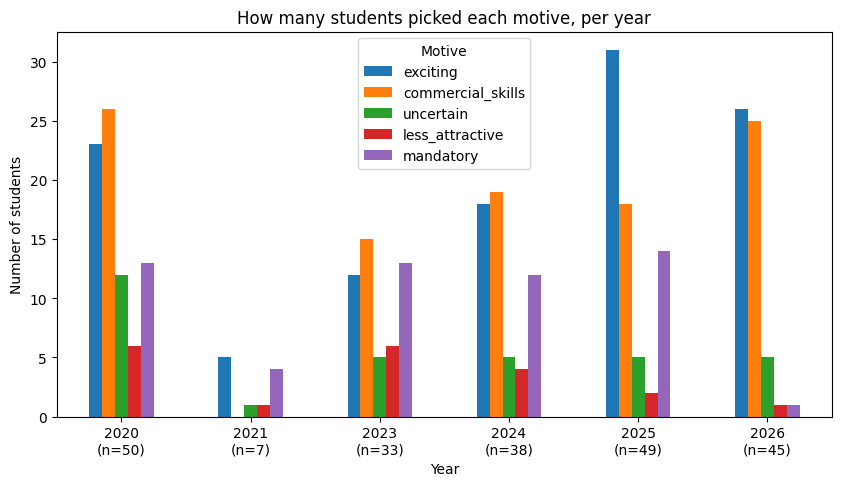

In [3]:
# Step 3: Bar chart - how many students picked each motive, per year
import matplotlib.pyplot as plt

plot_counts = counts.copy()
plot_counts.index = [f"{year}\n(n={sizes[year]})" for year in plot_counts.index]   # show n under the year

plot_counts.plot(kind="bar", figsize=(10, 5), rot=0)
plt.xlabel("Year")
plt.ylabel("Number of students")
plt.title("How many students picked each motive, per year")
plt.legend(title="Motive")
plt.show()

## Step 4: From counts to shares

To compare years of different sizes we use the **share** of students who picked a motive: the count divided by the number of students that year. For a 0/1 column, the **mean** is exactly that share.

For example, `mandatory` in 2026 is 1 out of 45 students, so the share is about 0.02.

**The shares are what we predict.** For each motive we have one number per year: that is our dataset for the regression (6 years, 5 motives).

In [10]:
# Step 4: Shares - the mean of a 0/1 column is the share of students who ticked it
shares = df.groupby("response_year")[motives].mean()

shares.round(2)

,exciting,commercial_skills,uncertain,less_attractive,mandatory
response_year,,,,,
2020,0.46,0.52,0.24,0.12,0.26
2021,0.71,0.00,0.14,0.14,0.57
2023,0.36,0.45,0.15,0.18,0.39
2024,0.47,0.50,0.13,0.11,0.32
2025,0.63,0.37,0.10,0.04,0.29
2026,0.58,0.56,0.11,0.02,0.02


## Step 5: Split by year

The model must be tested on data it has **not seen**. Here the split is by time:

- **Training data:** the years before 2026 (2020, 2021, 2023, 2024, 2025).
- **Test data:** 2026, the year we want to predict.

We do not shuffle the data. We train on the past and predict the future, as it would be in real life. There are only **5 training points** per motive, so everything we find is very uncertain.

In [11]:
# Step 5: Split by year - train on the past, test on 2026
train = shares[shares.index < 2026]     # shares for 2020-2025
test = shares.loc[2026]                 # the real shares in 2026

print("Training years:", list(train.index))
print("Test year: 2026")

Training years: [2020, 2021, 2023, 2024, 2025]
Test year: 2026


## Step 6: Baseline

The simplest prediction is: **2026 will look like last year**, so we predict the 2025 shares.

We measure the error with the **MAE** (mean absolute error) from the regression notes: on average, how far off is the prediction, in share points. An MAE of 0.10 means the prediction is off by 10 percentage points on average.

**Baseline MAE: 0.107.** The trend model has to beat this.

In [12]:
# Step 6: Baseline - predict that 2026 looks exactly like 2025
from sklearn.metrics import mean_absolute_error

baseline = train.iloc[-1]       # the last training year (2025)
print("Baseline MAE:", round(mean_absolute_error(test, baseline), 3))

Baseline MAE: 0.107


## Step 7: Linear regression on the year

For each motive we fit a straight line through the years: **share = b1 * year + b2**. Then we use the line to predict the share for 2026. This is the same linear regression as in the regression notes, with the year as the input `x` and the share as the output `y`.

- We fit **one line per motive**, so five small models.
- `X_train` must be a column of numbers, so we reshape the years with `reshape(-1, 1)`.
- `model.predict([[2026]])` reads off the line at 2026.

In [13]:
# Step 7: Linear regression - one straight line per motive (share against year)
from sklearn.linear_model import LinearRegression

X_train = train.index.values.reshape(-1, 1)     # the years as a column

predictions = {}
for motive in motives:
    model = LinearRegression()
    model.fit(X_train, train[motive])           # learn the trend 2020-2025
    predictions[motive] = model.predict([[2026]])[0]   # predict 2026

predicted = pd.Series(predictions)

results = pd.DataFrame({
    "actual 2026": test,
    "predicted (trend)": predicted,
    "baseline (2025)": baseline,
}).round(2)
results

,actual 2026,predicted (trend),baseline (2025)
exciting,0.58,0.53,0.63
commercial_skills,0.56,0.45,0.37
uncertain,0.11,0.08,0.10
less_attractive,0.02,0.07,0.04
mandatory,0.02,0.31,0.29


## Step 8: Evaluate

We compare the trend model with the baseline using the MAE, and look at the error for each motive.

| Motive | Actual 2026 | Trend | Baseline (2025) |
|---|---|---|---|
| exciting | 0.58 | 0.53 | 0.63 |
| commercial_skills | 0.56 | 0.45 | 0.37 |
| uncertain | 0.11 | 0.08 | 0.10 |
| less_attractive | 0.02 | 0.07 | 0.04 |
| mandatory | 0.02 | **0.31** | **0.29** |

**MAE: trend 0.104, baseline 0.107.** The trend is no better than just repeating last year.

- For four of the five motives the trend is close: within 3-11 points.
- **`mandatory` is way off** (predicted 0.31, actual 0.02). That single motive makes up over half of all the error.

In [14]:
# Step 8: Evaluate - mean absolute error (MAE) and the error per motive
print("Trend MAE:   ", round(mean_absolute_error(test, predicted), 3))
print("Baseline MAE:", round(mean_absolute_error(test, baseline), 3))

# error for each motive (in share points)
(results["predicted (trend)"] - results["actual 2026"]).abs().round(2)

Trend MAE:    0.104
Baseline MAE: 0.107


exciting             0.05
commercial_skills    0.11
uncertain            0.03
less_attractive      0.05
mandatory            0.29
dtype: float64

## Step 9: Plot the result

Actual 2026 against the trend prediction and the baseline, for each motive. The visual shows what the numbers say: the predictions are close for everything **except `mandatory`**, where both the trend and the baseline expect around 30% and the real value is about 2%.

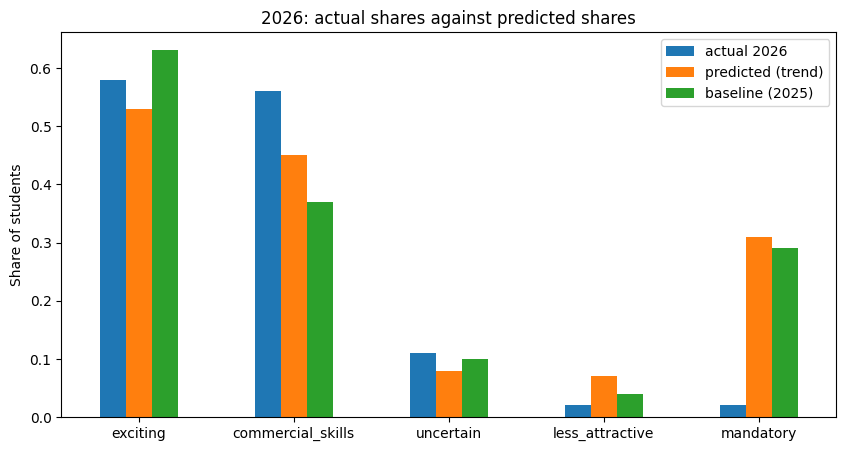

In [9]:
# Step 9: Plot - actual 2026 against the predictions
results.plot(kind="bar", figsize=(10, 5), rot=0)
plt.ylabel("Share of students")
plt.title("2026: actual shares against predicted shares")
plt.show()

## Conclusion

**Question:** Can the motives of 2026 be predicted from the years 2020-2025?

**Answer:** For most motives, roughly, but not better than simply repeating last year, and not at all for `mandatory`.

- **MAE:** trend 0.104 against baseline 0.107. A straight line through five years adds nothing over the previous year.
- **Exciting, commercial skills, uncertain and less attractive** are predicted within 3-11 percentage points. Their shares move up and down, but mostly stay in a similar range (about 0.4-0.6 for exciting and commercial skills, apart from the tiny 2021 group).
- **`mandatory` fails** (predicted 0.31, actual 0.02). The reason is not the model but the world: in 2026 the students could choose the course freely, so almost nobody ticked mandatory. A trend based on earlier years cannot know about a change like that.

**Why the result is limited**

- **Very few data points:** only 5 training years per motive. The 2021 point rests on just 7 students and is very noisy.
- **One year to test on:** a single year of 45 students can be a lucky or unlucky match for any model.
- **A straight line is a simple assumption:** it fits a smooth change over time, not a sudden break like the one in 2026.

**What we learned:** the share of students who find the course exciting or useful **stays in a similar range from year to year**, but the share of students who *had to* take it depends on how the course was set up, and no pattern in the old data could predict that.